# ProductPulse — Churn Prediction Model

One interpretable Logistic Regression model, per this project's tech stack.

## Why not just use the `is_churned` label from the EDA notebook directly

The EDA notebook found `recency_days` correlated with churn at r=0.75 — by
far the strongest signal. But that feature was computed **as of the current
snapshot**, which makes it close to circular: a churned user is silent
*because* they left, so "many days since last event" and "status = churned"
are nearly the same fact measured twice. A model built on that would look
great on paper and be useless in production, because you can't act on a
prediction of something that already happened.

**This notebook uses a proper time-based setup instead:** a cutoff 90 days
before the last observed data, restricted to users who were still paying
customers *at* that cutoff, with every feature computed using only data up to
the cutoff, predicting whether they churned in the 90 days *after* it. See
`sql/features/churn_model_features.sql` for the full construction.


**Review note:** Saved outputs predate the current review and have not been regenerated. This project uses outcome-conditioned synthetic behavior and reconstructed billing dates. Model scores and business interpretations are illustrative; see [known limitations](../docs/project_review.md).

## Setup

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from sqlalchemy import URL, create_engine, text
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, roc_auc_score, roc_curve,
                              confusion_matrix, ConfusionMatrixDisplay)

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)

load_dotenv('../.env')
db_url = URL.create(
    'postgresql+psycopg2',
    username=os.getenv('PGUSER'),
    password=os.getenv('PGPASSWORD', ''),
    host=os.getenv('PGHOST', 'localhost'),
    port=int(os.getenv('PGPORT', '5432')),
    database=os.getenv('PGDATABASE'),
)
engine = create_engine(db_url)

with open('../sql/features/churn_model_features.sql') as f:
    df = pd.read_sql(text(f.read()), engine)

print(df.shape)
df.head()


(4880, 13)


,user_id,plan,acquisition_channel,country,tenure_days_at_cutoff,recency_days_at_cutoff,events_last_30d,events_last_90d,sessions_last_90d,distinct_features_used,payments_before_cutoff,revenue_before_cutoff,churned_after_cutoff
0,0002-ORFBO,Pro,Partner,United States,194,0,14,23,7,9,6,393.60,0
1,0003-MKNFE,Pro,Referral,Germany,206,4,13,46,14,10,7,419.30,0
2,0013-MHZWF,Pro,Organic Search,United States,206,0,17,50,13,9,7,485.80,0
3,0013-SMEOE,Enterprise,Referral,Canada,2090,8,12,36,10,10,69,7569.30,0
4,0014-BMAQU,Enterprise,Referral,United Kingdom,1843,11,19,43,13,10,61,5163.65,0


## Class balance

In [2]:
n_pos = df['churned_after_cutoff'].sum()
n = len(df)
print(f"{n} users at risk as of the cutoff; {n_pos} ({n_pos/n:.1%}) churned in the following 90 days")
print()
print("This is a heavily imbalanced target. A model that always predicts "
      "'won't churn' would already score", f"{1 - n_pos/n:.1%} accuracy", "-- useless, but a reminder "
      "that accuracy alone is the wrong metric to judge this model on. class_weight='balanced' and "
      "precision/recall/ROC-AUC are used instead of plain accuracy below.")


4880 users at risk as of the cutoff; 107 (2.2%) churned in the following 90 days

This is a heavily imbalanced target. A model that always predicts 'won't churn' would already score 97.8% accuracy -- useless, but a reminder that accuracy alone is the wrong metric to judge this model on. class_weight='balanced' and precision/recall/ROC-AUC are used instead of plain accuracy below.


## Check multicollinearity before selecting features

Several of these engagement measures are almost certainly redundant with each
other by construction (more sessions inevitably means more events; payment
count and tenure move together almost in lockstep). Throwing all of them into
one logistic regression would inflate standard errors and make the individual
coefficients unstable and hard to trust — the opposite of "interpretable".
Checking correlation first, then deliberately trimming, is what makes the
final coefficients worth reading.


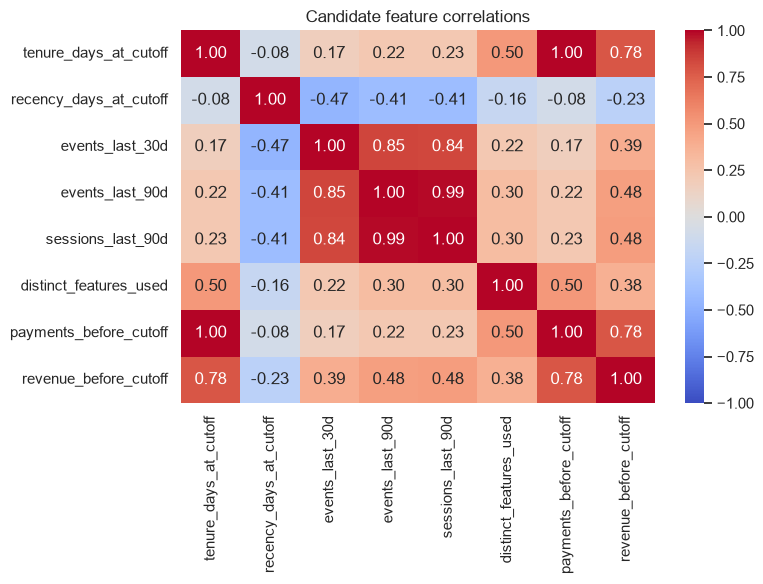

In [3]:
candidate_numeric = ['tenure_days_at_cutoff', 'recency_days_at_cutoff', 'events_last_30d',
                      'events_last_90d', 'sessions_last_90d', 'distinct_features_used',
                      'payments_before_cutoff', 'revenue_before_cutoff']

plt.figure(figsize=(8, 6))
sns.heatmap(df[candidate_numeric].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Candidate feature correlations')
plt.tight_layout()
plt.show()


As expected: `events_last_90d` / `sessions_last_90d` / `events_last_30d` move
together tightly, and `payments_before_cutoff` tracks `tenure_days_at_cutoff`
almost perfectly (payments happen ~monthly, so months paid ≈ months of
tenure). Final feature set keeps one representative from each redundant
group:

- `recency_days_at_cutoff` — how long since they last showed up (kept over the
  raw event/session counts — this is the more direct "have they gone quiet"
  signal the counts are really proxies for)
- `distinct_features_used` — breadth of adoption, not just volume of activity
- `tenure_days_at_cutoff` — dropped `payments_before_cutoff` as its near-duplicate
- `revenue_before_cutoff` — dollar value, distinct from raw activity counts
- `plan`, `acquisition_channel` — categorical business context


In [4]:
numeric_features = ['tenure_days_at_cutoff', 'recency_days_at_cutoff',
                     'distinct_features_used', 'revenue_before_cutoff']
categorical_features = ['plan', 'acquisition_channel']

X = pd.get_dummies(df[numeric_features + categorical_features], columns=categorical_features, drop_first=True)
y = df['churned_after_cutoff']

print(X.columns.tolist())
X.head()


['tenure_days_at_cutoff', 'recency_days_at_cutoff', 'distinct_features_used', 'revenue_before_cutoff', 'plan_Enterprise', 'plan_Pro', 'acquisition_channel_Organic Search', 'acquisition_channel_Paid Search', 'acquisition_channel_Paid Social', 'acquisition_channel_Partner', 'acquisition_channel_Referral']


,tenure_days_at_cutoff,recency_days_at_cutoff,distinct_features_used,revenue_before_cutoff,plan_Enterprise,plan_Pro,acquisition_channel_Organic Search,acquisition_channel_Paid Search,acquisition_channel_Paid Social,acquisition_channel_Partner,acquisition_channel_Referral
0,194,0,9,393.60,False,True,False,False,False,True,False
1,206,4,10,419.30,False,True,False,False,False,False,True
2,206,0,9,485.80,False,True,True,False,False,False,False
3,2090,8,10,7569.30,True,False,False,False,False,False,True
4,1843,11,10,5163.65,True,False,False,False,False,False,True


## Train / test split and scaling

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Scale numeric columns only -- fit on train, applied to test (no leakage from
# the held-out set into the scaling parameters). Scaling matters here beyond
# convergence: it's what makes the logistic regression coefficients below
# directly comparable to each other in magnitude.
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[numeric_features] = scaler.fit_transform(X_train[numeric_features])
X_test_scaled[numeric_features] = scaler.transform(X_test[numeric_features])

print(f"train: {len(X_train)} ({y_train.sum()} churned)  |  test: {len(X_test)} ({y_test.sum()} churned)")


train: 3660 (80 churned)  |  test: 1220 (27 churned)


## Fit the model

In [6]:
model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
y_proba = model.predict_proba(X_test_scaled)[:, 1]

print(classification_report(y_test, y_pred, target_names=['Retained', 'Churned']))
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba):.3f}")


              precision    recall  f1-score   support

    Retained       0.99      0.67      0.80      1193
     Churned       0.05      0.70      0.09        27

    accuracy                           0.67      1220
   macro avg       0.52      0.69      0.44      1220
weighted avg       0.97      0.67      0.78      1220

ROC-AUC: 0.747


**On that 0.05 precision for "Churned":** read in isolation this looks like a
bad model, but it's the expected shape of the result given the setup, not a
red flag. `class_weight='balanced'` deliberately shifts the decision boundary
to catch more of a rare class (recall 0.70 — 19 of 27 actual churners
correctly flagged) at the cost of many false positives, on top of a base
rate of only 2.2%. In production you would never use the default 0.5
threshold here anyway — you'd rank users by `predict_proba` and target
customer-success outreach at, say, the top 5-10% by predicted risk, and tune
that cutoff against the real cost of an outreach vs. the cost of a missed
churn. **ROC-AUC (0.747), which doesn't depend on a threshold, is the more
honest single-number read on this model** — meaningfully better than a coin
flip, appropriate for a first pass on a genuinely leakage-free setup with
~100 positive examples.


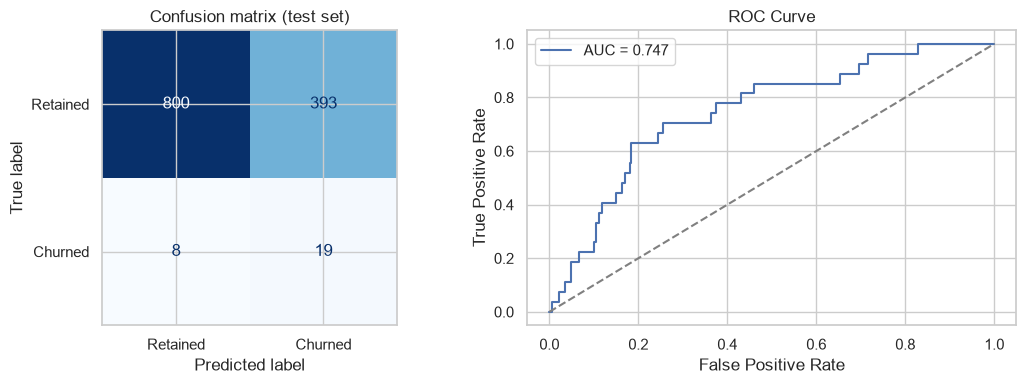

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['Retained', 'Churned']).plot(ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title('Confusion matrix (test set)')

fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[1].plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_test, y_proba):.3f}', color='#4C72B0')
axes[1].plot([0, 1], [0, 1], linestyle='--', color='grey')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve')
axes[1].legend()

plt.tight_layout()
plt.show()


**On the small positive class:** only ~100 churn events fall in this 90-day
window, out of 4,880 at-risk users — a real portfolio-scale limitation, not
a hidden flaw. Read the coefficients below as directionally reliable, not as
precise production-grade estimates; a real deployment would want a longer
observation history before trusting exact odds ratios.


## Feature importance

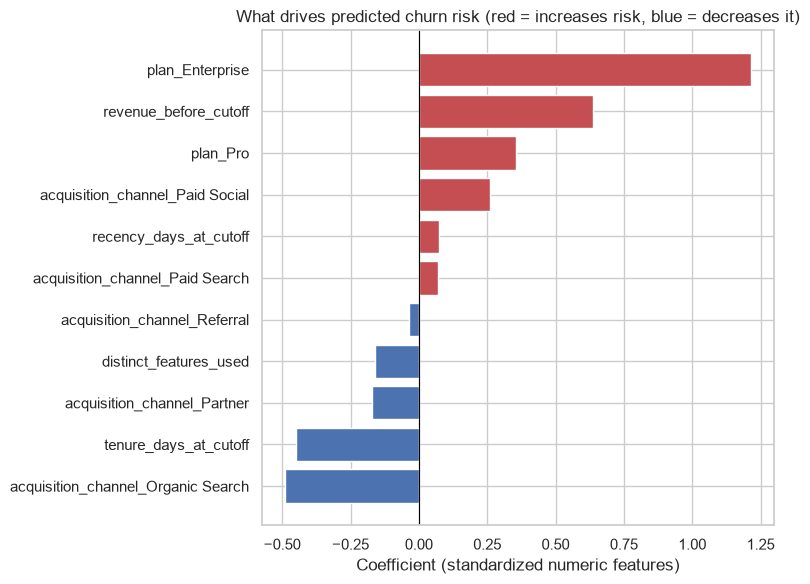

,feature,coefficient,odds_ratio
4,plan_Enterprise,1.213992,3.366899
3,revenue_before_cutoff,0.635568,1.888094
5,plan_Pro,0.353945,1.424677
8,acquisition_channel_Paid Social,0.260959,1.298175
1,recency_days_at_cutoff,0.073621,1.076398
7,acquisition_channel_Paid Search,0.070177,1.072698
10,acquisition_channel_Referral,-0.037450,0.963243
2,distinct_features_used,-0.159937,0.852198
9,acquisition_channel_Partner,-0.171298,0.842571
0,tenure_days_at_cutoff,-0.449413,0.638003


In [8]:
coef_df = pd.DataFrame({
    'feature': X.columns,
    'coefficient': model.coef_[0],
}).sort_values('coefficient')
coef_df['odds_ratio'] = np.exp(coef_df['coefficient'])

fig, ax = plt.subplots(figsize=(8, 6))
colors = ['#C44E52' if c > 0 else '#4C72B0' for c in coef_df['coefficient']]
ax.barh(coef_df['feature'], coef_df['coefficient'], color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Coefficient (standardized numeric features)')
ax.set_title('What drives predicted churn risk (red = increases risk, blue = decreases it)')
plt.tight_layout()
plt.show()

coef_df.sort_values('coefficient', ascending=False)


### Reading this in business language

The fitted coefficients tell a more interesting — and different — story than
Module 6's raw correlations alone would have suggested, which is exactly why
a multivariate model earns its place over eyeballing a correlation matrix.

- **Plan tier is the single strongest factor, and it runs the "wrong" way**:
  Enterprise customers have roughly **3.4x** the churn odds of Basic
  customers, Pro about **1.4x**, holding tenure/recency/adoption/revenue
  fixed. `revenue_before_cutoff` points the same direction (higher cumulative
  spend, higher risk). Read together, this looks like a renewal-scrutiny
  effect rather than a product-usage one: customers paying more tend to face
  tighter budget review and a higher bar to keep re-approving the spend, so
  the accounts most worth protecting are exactly the ones this model flags
  as highest-risk. That's a genuinely actionable, if slightly uncomfortable,
  finding — worth a dedicated Enterprise renewal/success motion, not just
  more self-serve engagement nudges.
- **Recency's effect shrinks a lot once other factors are in the model.**
  Module 6 found recency correlated with churn at r=0.75 on its own — the
  strongest signal in the dataset. Here, controlling for tenure and plan,
  its independent contribution (odds ratio 1.08 per std. dev.) is
  comparatively small. That gap is the point: much of what raw recency
  appeared to be telling us was really tenure and plan differences riding
  along with it. Isolating the two matters for where you'd actually spend a
  retention budget.
- **Tenure is genuinely protective on its own** (odds ratio 0.64 per std.
  dev.) — longer-standing customers are meaningfully less likely to churn in
  the next 90 days even after accounting for their plan and recent behavior.
  Ordinary survivorship: the relationships that were always going to break
  down early mostly already have.
- **Breadth of feature adoption has a modest protective effect** (odds ratio
  0.85) — real, but smaller than plan tier or tenure here. Still supports
  pushing new users toward trying multiple features early, just not as the
  single highest-leverage lever this particular model surfaced.
- **Acquisition channel differences are small** once plan and behavior are
  controlled for, with Paid Social the one channel showing a modest
  independent bump in risk (odds ratio 1.30 vs. Email).

**One honest caveat this dataset can't get around:** these are directional
reads from ~100 churn events, not a validated production model. The
Enterprise-risk finding in particular is exactly the kind of result that
deserves a second look with more data before anyone reorganizes a renewals
team around it — but "check whether high-value renewals are under-resourced
relative to their risk" is a reasonable next step to take from it, not an
overreach.
